In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

PARAMS = dict(alpha_C=0.4, alpha_B=0.3, alpha_T=0.8,
              gamma=7.0, beta=0.07, omega_C=1.2, omega_B=0.012,
              k=0.005, n=3)

def rhs(t: float, x: np.ndarray, p: dict) -> np.ndarray:
    S, C, B, T = x
    h = 1.0 / (1.0 + (C / p["k"])**p["n"])
    return np.array([
        -(p["alpha_C"] + p["alpha_B"] + p["alpha_T"])*S
          + p["gamma"]*(1.0-S-C-B-T),
        p["alpha_C"]*S - p["omega_C"]*h*C,
        p["alpha_B"]*S - p["omega_B"]*h*B,
        p["alpha_T"]*S - p["beta"]*T
    ])

def jacobian(x: np.ndarray, p: dict) -> np.ndarray:
    S, C, B, T = x
    q = (C / p["k"])**p["n"]
    h = 1.0 / (1.0 + q)
    hp = -(p["n"]/p["k"])*(C/p["k"])**(p["n"]-1)/(1+q)**2
    g = p["gamma"]
    return np.array([
        [-g-p["alpha_C"]-p["alpha_B"]-p["alpha_T"], -g, -g, -g],
        [p["alpha_C"], -p["omega_C"]*(h+C*hp), 0.0, 0.0],
        [p["alpha_B"], -p["omega_B"]*hp*B, -p["omega_B"]*h, 0.0],
        [p["alpha_T"], 0.0, 0.0, -p["beta"]]
    ])

def equilibrium(p: dict) -> np.ndarray:
    """Find one equilibrium. It is unique for the default and local Hopf examples.
    This function does not enumerate all equilibria for arbitrary parameters.
    """
    A = p["gamma"] + p["alpha_C"] + p["alpha_B"] + p["alpha_T"]
    r = p["alpha_B"]*p["omega_C"]/(p["alpha_C"]*p["omega_B"])
    def H(C):
        d = p["omega_C"]*C/(1+(C/p["k"])**p["n"])
        return ((A+p["gamma"]*p["alpha_T"]/p["beta"])*d
                +p["gamma"]*p["alpha_C"]*(1+r)*C
                -p["gamma"]*p["alpha_C"])
    C = brentq(H, 0.0, 1.0, xtol=1e-15)
    S = p["omega_C"]*C/(1+(C/p["k"])**p["n"])/p["alpha_C"]
    return np.array([S, C, r*C, p["alpha_T"]*S/p["beta"]])

def simulate(p: dict, x0=None, t_end=30000.0, method="Radau",
             rtol=1e-10, atol=1e-12):
    if any(v <= 0 for v in p.values()):
        raise ValueError("All model parameters must be positive.")
    eq = equilibrium(p)
    if x0 is None:
        x0 = eq + np.array([0.0, 1e-5, -1e-5, 0.0])
    x0 = np.asarray(x0, dtype=float)
    if x0.shape != (4,) or x0.min() < 0 or x0.sum() > 1+1e-12:
        raise ValueError("x0 must lie in the nonnegative physical simplex.")
    # events to pass to solve_ivp to watch during integration; solve_ivp will
    # record the times when these events occur (when they pass through 0)
    def crossing(t, x): # records number of times we pass through the equilibrium if oscillating (Poincare section)
        return x[1] - eq[1]
    crossing.direction = 1
    def maximum(t, x): # records local maxima of C(t) (oscillation peaks)
        return rhs(t, x, p)[1]
    maximum.direction = -1
    def minimum(t, x): # records local minima of C(t) (oscillation troughs)
        return rhs(t, x, p)[1]
    minimum.direction = 1
    options = {}
    if method in ("Radau", "BDF"):
        options["jac"] = lambda t, x: jacobian(x, p)
    sol = solve_ivp(
        lambda t, x: rhs(t, x, p), (0.0, t_end), x0,
        method=method, rtol=rtol, atol=atol, max_step=10.0,
        dense_output=True, events=[crossing, maximum, minimum], **options)
    if not sol.success:
        raise RuntimeError(sol.message)
    return eq, x0, sol

In [2]:
p = PARAMS.copy()
eq, x0, sol = simulate(p,method = "RK45")
eigenvalues = np.linalg.eigvals(jacobian(eq, p))
if len(sol.t_events[0]) < 4:
    raise RuntimeError("Not enough section crossings: increase the time horizon.")
period = np.diff(sol.t_events[0])[-1] # approximate period of the oscillation
t_cycle = np.linspace(0.0, period, 20001) # time points for one cycle of the oscillation
cycle = sol.sol(sol.t_events[0][-2] + t_cycle) # state values for one cycle of the oscillation
print("Equilibrium [S,C,B,T]:", eq)
print("Jacobian eigenvalues at equilibrium:", eigenvalues)
print("Initial condition:", x0)
#print("Last five periods:", np.diff(sol.t_events[0])[-5:])
print("Cycle minima:", cycle.min(axis=1))
print("Cycle maxima:", cycle.max(axis=1))
#print("Max componentwise successive-section difference:",
#      np.max(np.abs(np.diff(sol.y_events[0][-10:], axis=0))))

Equilibrium [S,C,B,T]: [0.00216054 0.01279848 0.95988615 0.02469186]
Jacobian eigenvalues at equilibrium: [-7.00873864+0.j        -1.46590152+0.j         0.01380776+0.0271664j
  0.01380776-0.0271664j]
Initial condition: [0.00216054 0.01280848 0.95987615 0.02469186]
Cycle minima: [1.55784956e-04 5.15845127e-03 9.22343120e-01 1.79158770e-03]
Cycle maxima: [0.00759621 0.04273425 0.97255597 0.06235733]


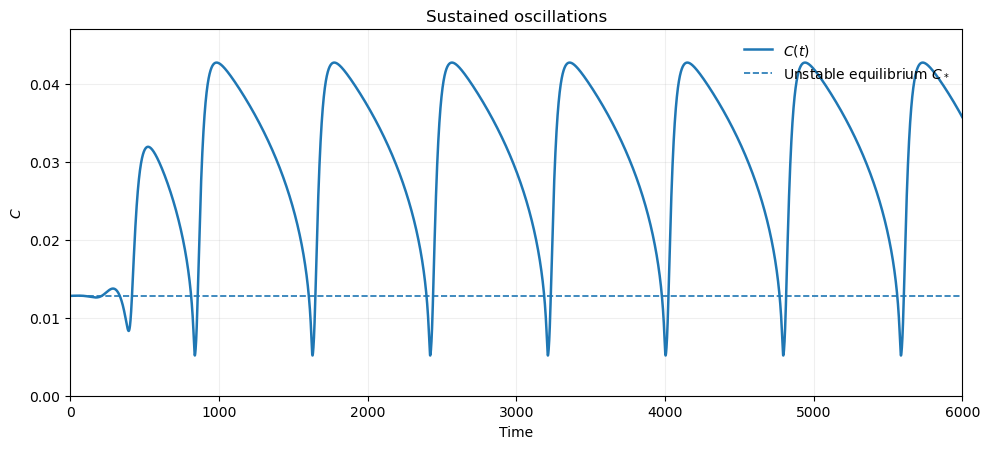

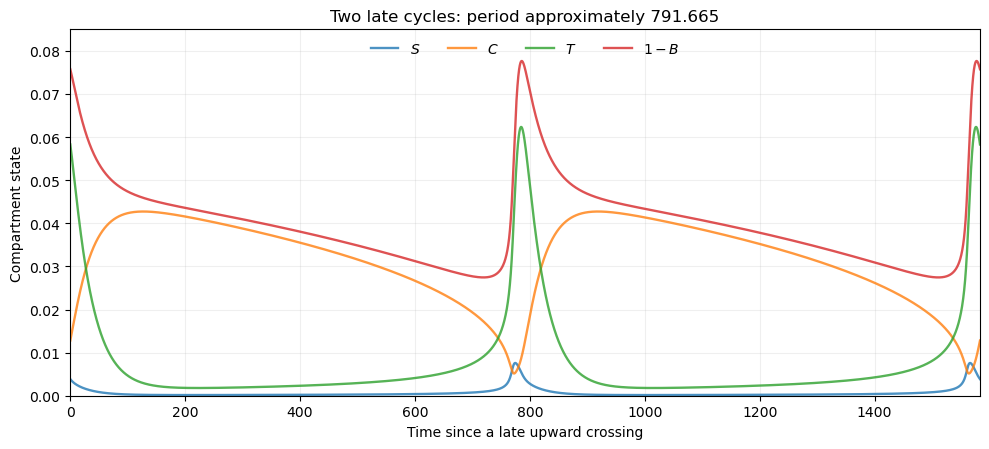

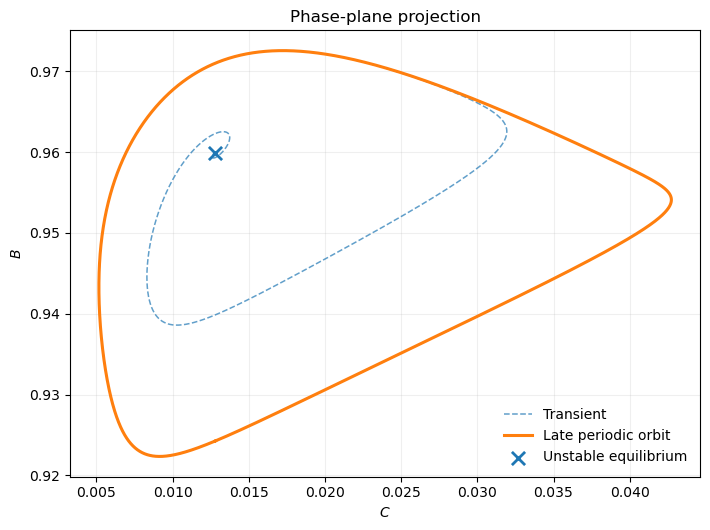

In [3]:
t = np.linspace(0.0, 6000.0, 24001)
y = sol.sol(t)
fig = plt.figure(figsize=(10, 4.6))
ax = fig.add_subplot(111)
ax.plot(t, y[1], linewidth=1.8, label=r"$C(t)$")
ax.axhline(eq[1], linestyle="--", linewidth=1.2,
           label=r"Unstable equilibrium $C_*$")
ax.set(xlabel="Time", ylabel=r"$C$",
       title="Sustained oscillations",
       xlim=(0, 6000), ylim=(0, 0.047))
ax.legend(loc="upper right", frameon=False)
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

t = np.linspace(0.0, 2*period, 16001)
y = sol.sol(sol.t_events[0][-3] + t)
fig = plt.figure(figsize=(10, 4.6))
ax = fig.add_subplot(111)
for values, label in [(y[0], r"$S$"), (y[1], r"$C$"),
                      (y[3], r"$T$"), (1-y[2], r"$1-B$")]:
    ax.plot(t, values, linewidth=1.7, label=label, alpha = 0.8)
ax.set(xlabel="Time since a late upward crossing",
       ylabel="Compartment state",
       title=f"Two late cycles: period approximately {period:.3f}",
       xlim=(0, 2*period), ylim=(0, 0.085))
ax.legend(loc="upper center", ncol=4, frameon=False)
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

yp = sol.sol(np.linspace(0.0, 1500.0, 15001))
fig = plt.figure(figsize=(7.2, 5.4))
ax = fig.add_subplot(111)
ax.plot(yp[1], yp[2], linestyle="--", linewidth=1.1,
        alpha=0.7, label="Transient")
ax.plot(cycle[1], cycle[2], linewidth=2.2, label="Late periodic orbit")
ax.scatter([eq[1]], [eq[2]], marker="x", s=90, linewidths=2,
           label="Unstable equilibrium", zorder=5)
ax.set(xlabel=r"$C$", ylabel=r"$B$",
       title="Phase-plane projection")
ax.legend(loc="lower right", frameon=False)
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()